# _**Notebook Setup**_

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

# **Stages of task**
    1. Loading the data.
    2. Data cleaning.
    3. EDA.
    4. Text Preprocessing.
    5. Model Building.
    6. Improvement.
    7. Conclusion.

In [2]:
import os
import pandas as pd
import numpy as np
from kagglehub import dataset_download

## _**1. Load the data**_

In [3]:
path = dataset_download("uciml/sms-spam-collection-dataset")

In [4]:
df = pd.read_csv(os.path.join(path, "spam.csv"), encoding="latin-1")

In [5]:
print(df)

        v1                                                 v2 Unnamed: 2  \
0      ham  Go until jurong point, crazy.. Available only ...        NaN   
1      ham                      Ok lar... Joking wif u oni...        NaN   
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...        NaN   
3      ham  U dun say so early hor... U c already then say...        NaN   
4      ham  Nah I don't think he goes to usf, he lives aro...        NaN   
...    ...                                                ...        ...   
5567  spam  This is the 2nd time we have tried 2 contact u...        NaN   
5568   ham              Will Ì_ b going to esplanade fr home?        NaN   
5569   ham  Pity, * was in mood for that. So...any other s...        NaN   
5570   ham  The guy did some bitching but I acted like i'd...        NaN   
5571   ham                         Rofl. Its true to its name        NaN   

     Unnamed: 3 Unnamed: 4  
0           NaN        NaN  
1           NaN        NaN  


## _**2. Data Cleaning**_

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   v1          5572 non-null   str  
 1   v2          5572 non-null   str  
 2   Unnamed: 2  50 non-null     str  
 3   Unnamed: 3  12 non-null     str  
 4   Unnamed: 4  6 non-null      str  
dtypes: str(5)
memory usage: 217.8 KB


In [7]:
# Drop the irrelavant columns
df.drop(columns=["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"], inplace=True)

In [8]:
df.sample(5)

,v1,v2
3396,ham,Heehee that was so funny tho
5136,ham,There are some nice pubs near here or there is...
3081,ham,"And very importantly, all we discuss is betwee..."
4690,ham,Surly ill give it to you:-) while coming to re...
623,ham,"sorry, no, have got few things to do. may be i..."


In [9]:
# Renaming the columns
df.rename(columns={"v1": "target", "v2":"text"}, inplace=True)

In [10]:
from sklearn.preprocessing import LabelEncoder
encoder =  LabelEncoder()

In [11]:
df['target'] = encoder.fit_transform(df['target'])

In [12]:
#Check for missing values
df.isnull().sum()

target    0
text      0
dtype: int64

In [13]:
#Check for duplicate values
df.duplicated().sum()

np.int64(403)

In [14]:
df = df.drop_duplicates(keep='first')

In [15]:
df.shape

(5169, 2)

## _**3. Exploratory Data Analysis (EDA)**_

In [16]:
df['target'].value_counts()

target
0    4516
1     653
Name: count, dtype: int64

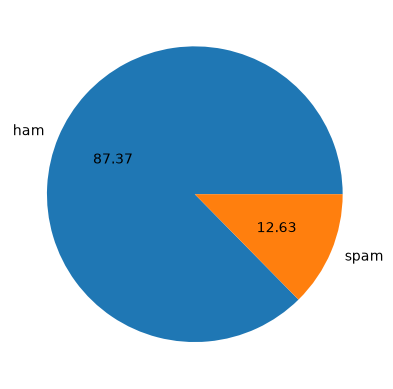

In [17]:
import matplotlib.pyplot as plt
plt.pie(df['target'].value_counts(), labels=['ham', 'spam'], autopct='%0.2f')
plt.show()

In [ ]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

In [19]:
#Number of Characters
df["num_characters"] = df['text'].apply(len)

In [20]:
#Number of Words
df["num_words"] = df['text'].apply (lambda x:len(nltk.word_tokenize(x)))

In [21]:
#Number of Sectences
df["num_sentences"] = df['text'].apply (lambda x:len(nltk.sent_tokenize(x)))

In [22]:
df.head()

,target,text,num_characters,num_words,num_sentences
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1


In [23]:
df[['num_characters', 'num_words', 'num_sentences']].describe()

,num_characters,num_words,num_sentences
count,5169.000000,5169.000000,5169.000000
mean,78.977945,18.460437,1.965564
std,58.236293,13.334441,1.448541
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,60.000000,15.000000,1.000000
75%,117.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


In [24]:
#Ham messages 
df[df['target'] == 0][['num_characters', 'num_words', 'num_sentences']].describe()

,num_characters,num_words,num_sentences
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.128432,1.820195
std,56.358207,13.504730,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [25]:
#spam messages 
df[df['target'] == 1][['num_characters', 'num_words', 'num_sentences']].describe()

,num_characters,num_words,num_sentences
count,653.000000,653.000000,653.000000
mean,137.891271,27.672282,2.970904
std,30.137753,7.010932,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


In [26]:
import seaborn as sns

<Axes: xlabel='num_characters', ylabel='Count'>

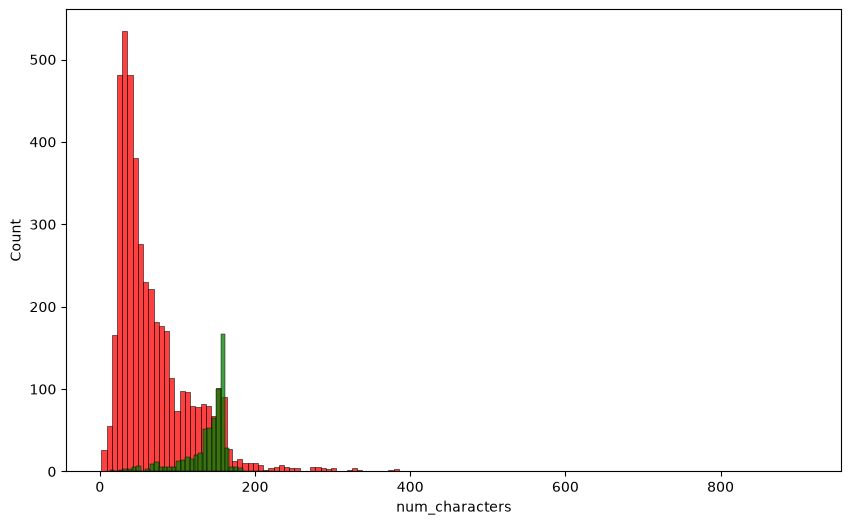

In [27]:
plt.figure(figsize=(10, 6))
sns.histplot(df[df['target'] == 0]['num_characters'], color='red', )
sns.histplot(df[df['target'] == 1]['num_characters'], color='green')

<Axes: xlabel='num_words', ylabel='Count'>

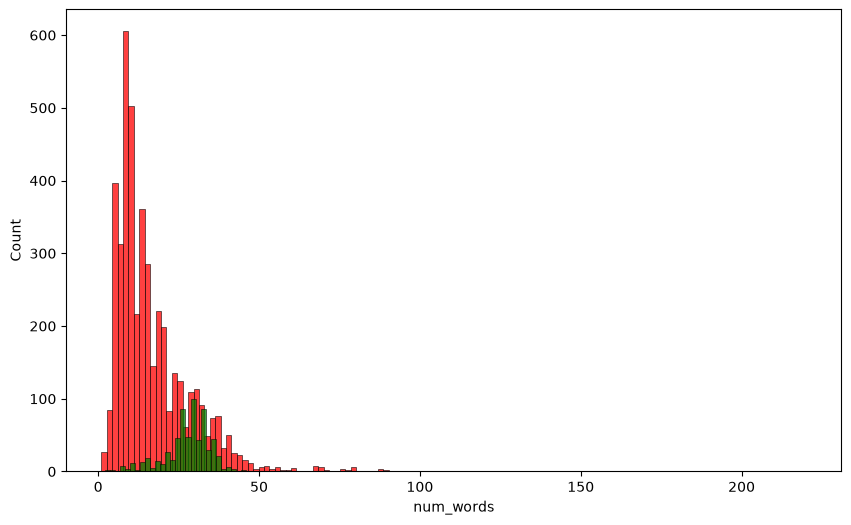

In [28]:
plt.figure(figsize=(10, 6))
sns.histplot(df[df['target'] == 0]['num_words'], color='red', )
sns.histplot(df[df['target'] == 1]['num_words'], color='green')

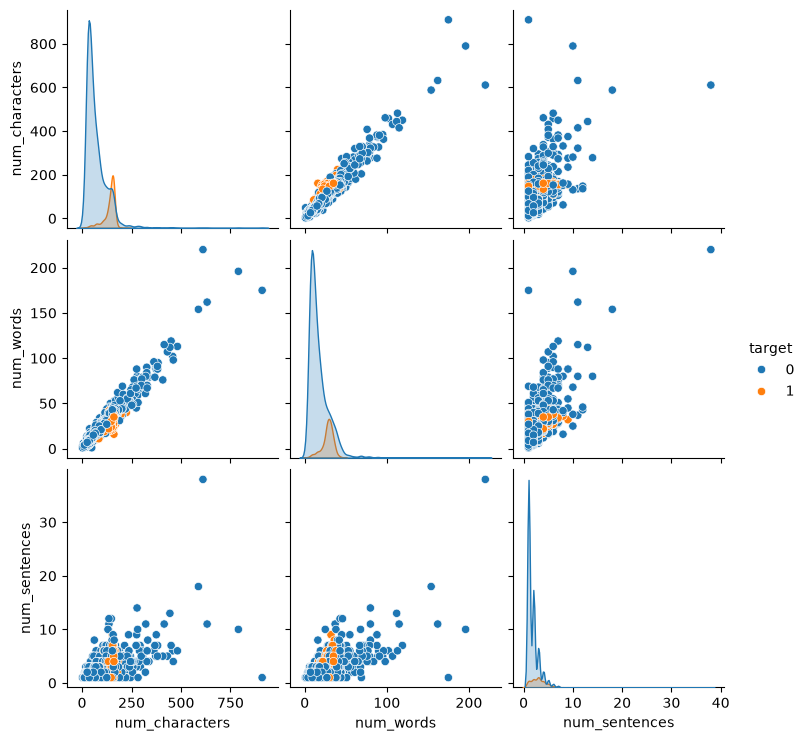

In [29]:
sns.pairplot(df, hue='target')

<Axes: >

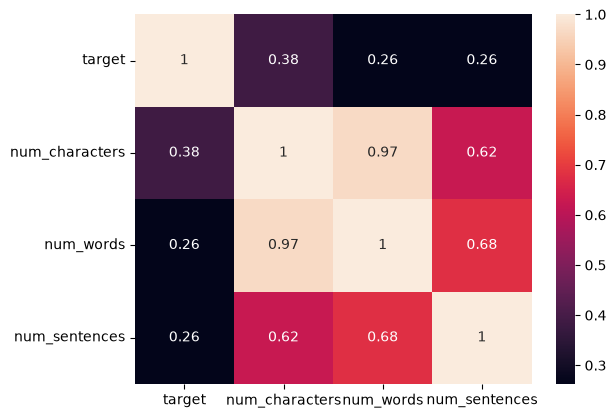

In [30]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

## _**4. Data Preprocessing**_
* Lower case
* Tokenization
* Remove special characters
* Remove stopwords and punctuations
* Stemming

In [ ]:
from nltk.corpus import stopwords
nltk.download('stopwords')
import string
from nltk.stem.porter import PorterStemmer
ps = PorterStemmer()

In [32]:
def transform_text(text):
    text = text.lower()
    text = nltk.word_tokenize(text)
    y = []
    for i in text:
        if i.isalnum():
            y.append(i)
    text = y[:]
    y.clear()

    for i in text:
        if i not in stopwords.words('english') and i not in string.punctuation:
            y.append(i)

    text = y[:]
    y.clear()

    for i in text:
        y.append(ps.stem(i))
    
    return " ".join(y)

In [33]:
transform_text("I Loved the YOuTube lectures, what about you?")

'love youtub lectur'

In [34]:
df["transformed_text"] = df['text'].apply(transform_text)

In [35]:
df.head()

,target,text,num_characters,num_words,num_sentences,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though


In [36]:
from wordcloud import WordCloud
wc = WordCloud(width=500, height=500, min_font_size=10, background_color="white")

In [37]:
spam_wc = wc.generate(df[df['target'] == 1]["transformed_text"].str.cat(sep=" "))

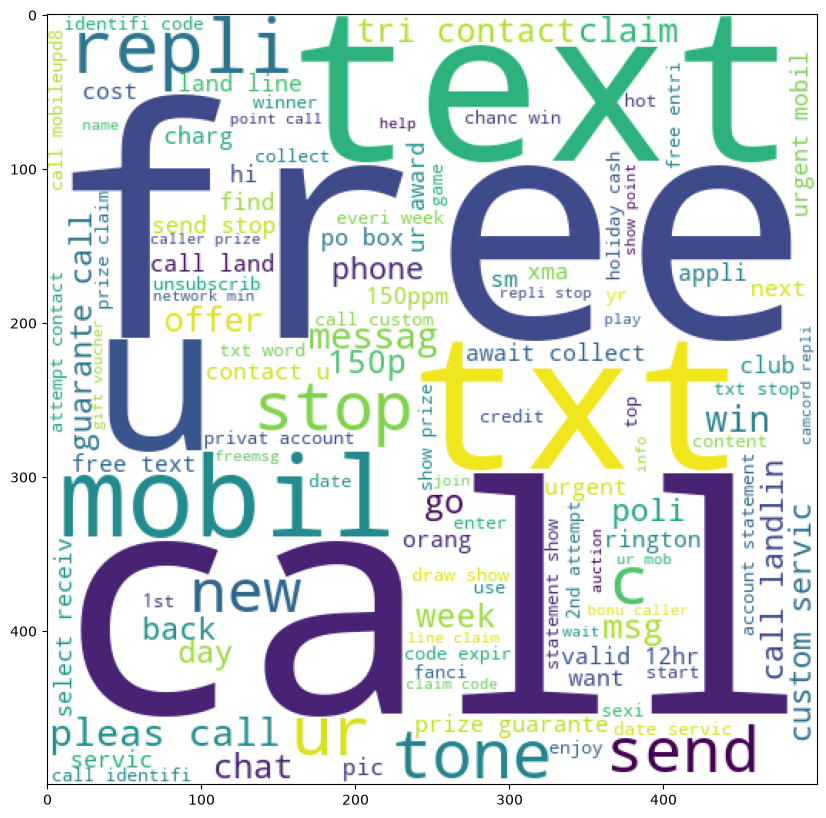

In [38]:
plt.figure(figsize=(10,10))
plt.imshow(spam_wc)

In [39]:
ham_wc = wc.generate(df[df['target'] == 0]["transformed_text"].str.cat(sep=" "))

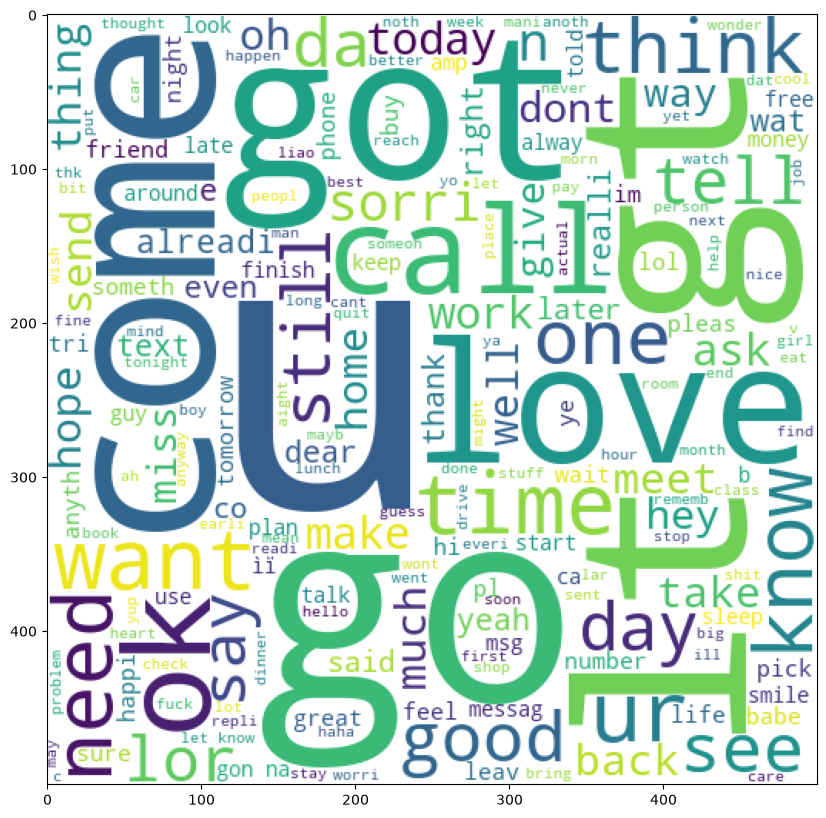

In [40]:
plt.figure(figsize=(10,10))
plt.imshow(ham_wc)

## _**5. Model Building**_

In [41]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer()

In [42]:
x = tfidf.fit_transform(df['transformed_text']).toarray()

In [43]:
x.shape

(5169, 6715)

In [44]:
y = df['target'].values

In [45]:
y

array([0, 0, 1, ..., 0, 0, 0], shape=(5169,))

In [46]:
from sklearn.model_selection import train_test_split

In [47]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=2)

In [48]:
x_train.shape

(3876, 6715)

In [49]:
x_test.shape

(1293, 6715)

In [50]:
x_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(3876, 6715))

In [51]:
y_train

array([0, 0, 0, ..., 0, 0, 0], shape=(3876,))

In [52]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, precision_score

In [53]:
gnb = GaussianNB()
mnb = MultinomialNB()
bnb = BernoulliNB()

In [54]:
gnb.fit(x_train,y_train)
y_pred1 = gnb.predict(x_test)
accuracy = accuracy_score(y_test, y_pred1)
Precision = precision_score(y_test, y_pred1)
print(f"Accruracy: {accuracy * 100:.2f}% ")
print(f"Precision: {Precision * 100:.2f}% ")

Accruracy: 87.01% 
Precision: 49.08% 


In [55]:
mnb.fit(x_train,y_train)
y_pred2 = mnb.predict(x_test)
accuracy = accuracy_score(y_test, y_pred2)
Precision = precision_score(y_test, y_pred2)
print(f"Accruracy: {accuracy * 100:.2f}% ")
print(f"Precision: {Precision * 100:.2f}% ")

Accruracy: 95.98% 
Precision: 100.00% 


In [56]:
bnb.fit(x_train,y_train)
y_pred3 = bnb.predict(x_test)
accuracy = accuracy_score(y_test, y_pred3)
Precision = precision_score(y_test, y_pred3)
print(f"Accruracy: {accuracy * 100:.2f}% ")
print(f"Precision: {Precision * 100:.2f}% ")

Accruracy: 96.98% 
Precision: 97.69% 


## _**6. Improvement.**_

In [57]:
tfidf = TfidfVectorizer(max_features = 3000)

In [58]:
x = tfidf.fit_transform(df['transformed_text']).toarray()

In [59]:
x.shape

(5169, 3000)

In [60]:
y = df['target'].values

In [61]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=3)

In [62]:
x_train.shape

(4135, 3000)

In [63]:
x_test.shape

(1034, 3000)

In [64]:
x_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(4135, 3000))

In [65]:
gnb.fit(x_train,y_train)
y_pred1 = gnb.predict(x_test)
accuracy = accuracy_score(y_test, y_pred1)
Precision = precision_score(y_test, y_pred1)
print(f"Accruracy: {accuracy * 100:.2f}% ")
print(f"Precision: {Precision * 100:.2f}% ")

Accruracy: 86.17% 
Precision: 49.38% 


In [66]:
mnb.fit(x_train,y_train)
y_pred2 = mnb.predict(x_test)
accuracy = accuracy_score(y_test, y_pred2)
Precision = precision_score(y_test, y_pred2)
print(f"Accruracy: {accuracy * 100:.2f}% ")
print(f"Precision: {Precision * 100:.2f}% ")

Accruracy: 97.00% 
Precision: 100.00% 


In [67]:
bnb.fit(x_train,y_train)
y_pred3 = bnb.predict(x_test)
accuracy = accuracy_score(y_test, y_pred3)
Precision = precision_score(y_test, y_pred3)
print(f"Accruracy: {accuracy * 100:.2f}% ")
print(f"Precision: {Precision * 100:.2f}% ")

Accruracy: 97.87% 
Precision: 99.17% 


## _**7. Conclusion.**_

In conclusion the Model that was trained using the **Naive bayes** method using the **Multi-Nominal Naive bayes (MultinomialNB)** algorithm achieved an **Accuracy of 97.00%** and a **Prcision of 100%**, which means the model is precisily identifying spam mail from Ham/normal mail